In [1]:
import pandas as pd
df = pd.read_csv("https://raw.githubusercontent.com/papayuh/datn1370-datasets/main/data/houston_weather.csv")
df.head()

,date,temp_high_f,temp_low_f,rain_in,wind_mph,season,rain_status
0,2022-01-01,84.9,71.1,0.0,12.8,winter,no measurable rain
1,2022-01-02,72.0,34.0,0.0,19.9,winter,no measurable rain
2,2022-01-03,55.0,33.1,0.0,5.4,winter,no measurable rain
3,2022-01-04,69.1,42.1,0.0,6.7,winter,no measurable rain
4,2022-01-05,80.1,52.0,0.0,6.9,winter,no measurable rain


In [2]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1092 entries, 0 to 1091
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         1092 non-null   object 
 1   temp_high_f  1092 non-null   float64
 2   temp_low_f   1092 non-null   float64
 3   rain_in      1092 non-null   float64
 4   wind_mph     1092 non-null   float64
 5   season       1092 non-null   object 
 6   rain_status  1092 non-null   object 
dtypes: float64(4), object(3)
memory usage: 59.8+ KB


,temp_high_f,temp_low_f,rain_in,wind_mph
count,1092.000000,1092.000000,1092.000000,1092.000000
mean,82.530037,64.506227,0.112793,9.070788
std,13.189279,13.786121,0.377519,3.341388
min,34.000000,17.200000,0.000000,2.500000
25%,73.900000,54.000000,0.000000,6.500000
50%,84.450000,68.000000,0.000000,8.500000
75%,93.000000,77.000000,0.010000,11.400000
max,109.000000,84.000000,6.650000,24.600000


In [3]:
# AI-assisted
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year

# AI-assisted
hot_days = (
    df[df["temp_high_f"] >= 100]
    .groupby("year")
    .size()
    .reindex(sorted(df["year"].unique()), fill_value=0)
)

print(df["year"].value_counts().sort_index())
hot_days

year
2022    364
2023    362
2024    366
Name: count, dtype: int64


,0
year,
2022,16
2023,39
2024,8


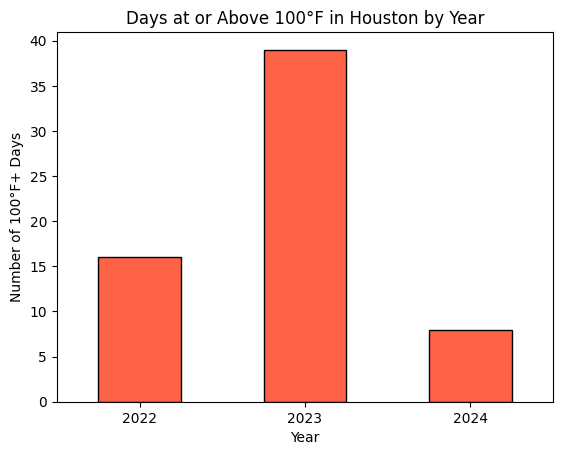

In [4]:
import matplotlib.pyplot as plt

hot_days.plot(kind="bar", color="tomato", edgecolor="black")
plt.title("Days at or Above 100°F in Houston by Year")
plt.xlabel("Year")
plt.ylabel("Number of 100°F+ Days")
plt.xticks(rotation=0)
plt.show()

**Finding:** Houston didn't get steadily hotter from 2022 to 2024. In 2023 the high hit 100°F or more on 39 days, which is more than double the 16 days in 2022. Then 2024 dropped to just 8. With only three years of data, 2023 looks like an outlier year, not the start of a trend.

**Why a bar chart:** I'm comparing a single count (the number of 100°F+ days) across separate groups (years). Bar charts make it easy to compare those totals at a glance.

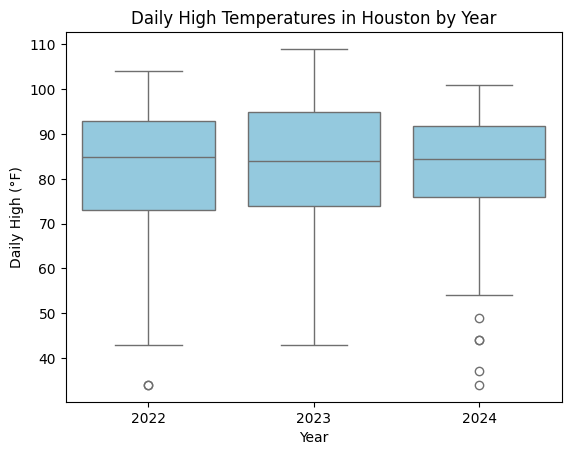

In [5]:
import seaborn as sns

sns.boxplot(data=df, x="year", y="temp_high_f", color="skyblue")
plt.title("Daily High Temperatures in Houston by Year")
plt.xlabel("Year")
plt.ylabel("Daily High (°F)")
plt.show()

**Finding:** The typical day didn't get hotter. The median daily high stayed around 84 to 85°F all three years. 2023 stands out at the top: its upper quartile and its max (about 109°F) are the highest of the three years, which matches the spike in 100°F+ days. 2024 had the tightest middle range, but it also had the most cold outliers, with several days below 50°F.

**Why a box plot:** I wanted to compare the full spread of daily highs across years, not just the extreme days. A box plot shows the median, the middle 50%, and the outliers for each year side by side, so I can see whether the whole year shifted or just the hottest days.

**Reflection:** The prep step gave me the most trouble. The date column loaded as text, so I had to convert it with pd.to_datetime before I could pull out the year. I also learned that groupby drops any year with zero 100°F days, so I used reindex to keep every year in the count. I used AI for the data-prep code (marked # AI-assisted) and accepted it after checking that each year had close to 365 days. My conclusion is that three years isn't enough to say Houston is getting hotter. 2023 was an extreme year, but the typical day stayed about the same.